In [1]:
import openturns as ot
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from joblib import dump, load

from surrogate_func import pca_reconstruction_error, sobol_error_trials, train_PCE, test_model
from surrogate_func import define_param_list, run_calibration, determine_sobol, pca_displacement_field
from helper_func import plot_pca_reconerror, plot_sobol_indices_cal, plot_errors, import_measurements, plot_sobol
from helper_func import plot_pca_fields
from surrogate_func import predict_deformation

In [2]:
# Import samples
run_name = "calibration"
sampletype = "U"

## Deformations and parameter logs
U_raw = pd.read_csv(f"../FEM_Samples/Calibration/{run_name}_BP_{sampletype}.csv", index_col=0)
param = pd.read_csv(f"../FEM_Samples/Calibration/{run_name}_log.csv", index_col=0)
Z_raw = U_raw.index.values
Z = np.linspace(Z_raw[0], Z_raw[-1], 100)

display(U_raw.head())
display(param.head())

## Preprocess samples
U = pd.DataFrame()
for run in param.index:
    U_temp = pd.DataFrame(index=Z)
    U_temp[f'run_{run}'] = np.interp(Z, Z_raw, U_raw[f"U_{run_name}_P8_R{run}"] - U_raw[f"U_{run_name}_P4_R{run}"])
    U = pd.concat([U, U_temp], axis=1)
    # U[f'run_{run}'] = U[f'run_{run}'] - U[f'run_{run}'].iloc[0]

display(U.head())
U = U.T.values
X = param.drop(columns=['Time','psi_A','psi_C', 'E_A', 'phi_C']).copy().values

,U_calibration_P4_R0,U_calibration_P5_R0,U_calibration_P6_R0,U_calibration_P7_R0,U_calibration_P8_R0,U_calibration_P4_R1,U_calibration_P5_R1,U_calibration_P6_R1,U_calibration_P7_R1,U_calibration_P8_R1,...,U_calibration_P4_R121,U_calibration_P5_R121,U_calibration_P6_R121,U_calibration_P7_R121,U_calibration_P8_R121,U_calibration_P4_R122,U_calibration_P5_R122,U_calibration_P6_R122,U_calibration_P7_R122,U_calibration_P8_R122
Z,,,,,,,,,,,,,,,,,,,,,
-35.500000,-0.334363,1.111772,2.625071,3.485218,3.631877,-0.391817,1.317625,3.057949,4.068151,4.099708,...,-0.339947,1.203212,2.822742,3.601207,3.695557,-0.334478,1.156956,2.750123,3.484895,3.601574
-34.366514,-0.418746,0.763086,2.257118,3.337147,3.884770,-0.487053,0.996022,2.707337,3.848815,4.297917,...,-0.417387,0.882225,2.468252,3.373682,3.833969,-0.407483,0.837467,2.392146,3.256797,3.719052
-34.354769,-0.420620,0.759456,2.253483,3.336744,3.887351,-0.488656,0.992847,2.704091,3.847727,4.299582,...,-0.419036,0.878887,2.464720,3.372455,3.835178,-0.409101,0.834115,2.388543,3.255484,3.720063
-33.233029,-0.496890,0.433509,1.914430,3.237472,4.202770,-0.577508,0.688289,2.378535,3.672058,4.553585,...,-0.489750,0.577286,2.137196,3.190558,4.031258,-0.475418,0.534549,2.057827,3.073725,3.895739
-33.221283,-0.498362,0.430349,1.911718,3.238512,4.208555,-0.578856,0.685331,2.375657,3.671789,4.557849,...,-0.491052,0.574313,2.134347,3.190283,4.034991,-0.476679,0.531597,2.054956,3.073435,3.899257


,Time,E_A,E_B,E_C,phi_A,phi_B,phi_C,psi_A,psi_C
run,,,,,,,,,
0,3261.70,50000.0,12000.0,87000.0,38.7,35.4,39.7,5.8,6.0
1,2427.31,50000.0,18000.0,58000.0,38.7,35.4,39.7,5.8,6.0
2,3333.54,50000.0,18000.0,87000.0,38.7,35.4,39.7,5.8,6.0
3,2653.05,50000.0,12000.0,58000.0,38.7,37.2,39.7,5.8,6.0
4,3043.97,50000.0,12000.0,87000.0,38.7,37.2,39.7,5.8,6.0


,run_0,run_1,run_2,run_3,run_4,run_5,run_6,run_7,run_8,run_9,...,run_113,run_114,run_115,run_116,run_117,run_118,run_119,run_120,run_121,run_122
-35.500000,3.966240,4.491525,3.900077,4.579674,3.982379,4.539191,3.931208,4.473400,3.907535,4.462553,...,4.064242,3.937272,4.049064,3.949423,3.996789,3.893338,4.090435,3.971982,4.035504,3.936051
-35.171717,4.063923,4.576513,3.959279,4.707317,4.071703,4.610934,3.977018,4.612051,4.004680,4.539507,...,4.126411,3.997476,4.159353,4.050720,4.077978,3.968693,4.178771,4.055138,4.098020,3.991220
-34.843434,4.161605,4.661501,4.018481,4.834960,4.161026,4.682678,4.022828,4.750701,4.101826,4.616460,...,4.188580,4.057680,4.269642,4.152018,4.159167,4.044047,4.267106,4.138295,4.160535,4.046388
-34.515152,4.259288,4.746490,4.077682,4.962603,4.250350,4.754421,4.068638,4.889352,4.198971,4.693414,...,4.250749,4.117885,4.379931,4.253316,4.240356,4.119401,4.355442,4.221451,4.223051,4.101557
-34.186869,4.366598,4.839555,4.145576,5.099497,4.349114,4.834025,4.122991,5.037463,4.305714,4.778409,...,4.321484,4.186767,4.499805,4.364248,4.330457,4.203722,4.453006,4.313901,4.294147,4.165385


n_components: 1, error_avg: 0.0079
n_components: 2, error_avg: 0.0026
n_components: 3, error_avg: 0.0008
n_components: 4, error_avg: 0.0002
n_components: 5, error_avg: 0.0001
n_components: 6, error_avg: 0.0001
n_components: 7, error_avg: 0.0000
n_components: 8, error_avg: 0.0000
n_components: 9, error_avg: 0.0000
n_components: 10, error_avg: 0.0000


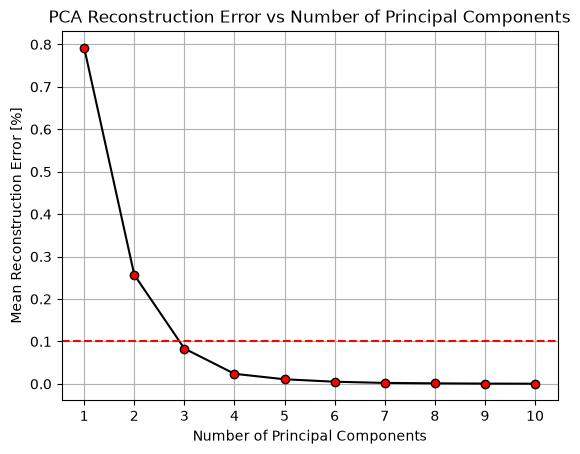

In [3]:
# Test optimal number of PCA components
errors = []
for n_components in range(1, 11):
    error_avg, error_all = pca_reconstruction_error(U, n_components)
    errors.append(error_avg)
    print(f"n_components: {n_components}, error_avg: {error_avg:.4f}")

plot_pca_reconerror(errors)

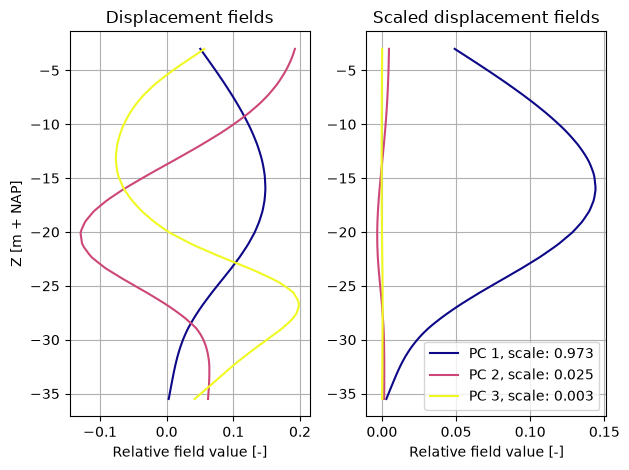

In [4]:
pc_fields, pc_fields_scaled, importance = pca_displacement_field(U, 3)

plot_pca_fields(pc_fields, pc_fields_scaled, importance, Z)

In [5]:
# Trial and error analysis for Sobol indices
n_trials = 1000
n_modes = 3
n_degrees = 10

run = False # change to True to run the Sobol error trials (takes ~15 min for 1000 trials)

if run:
      R2, RMSE, GNAE, sobol_first, sobol_total \
      = sobol_error_trials(n_trials=n_trials, n_modes=n_modes, n_degrees=n_degrees, X_raw=X, U=U)

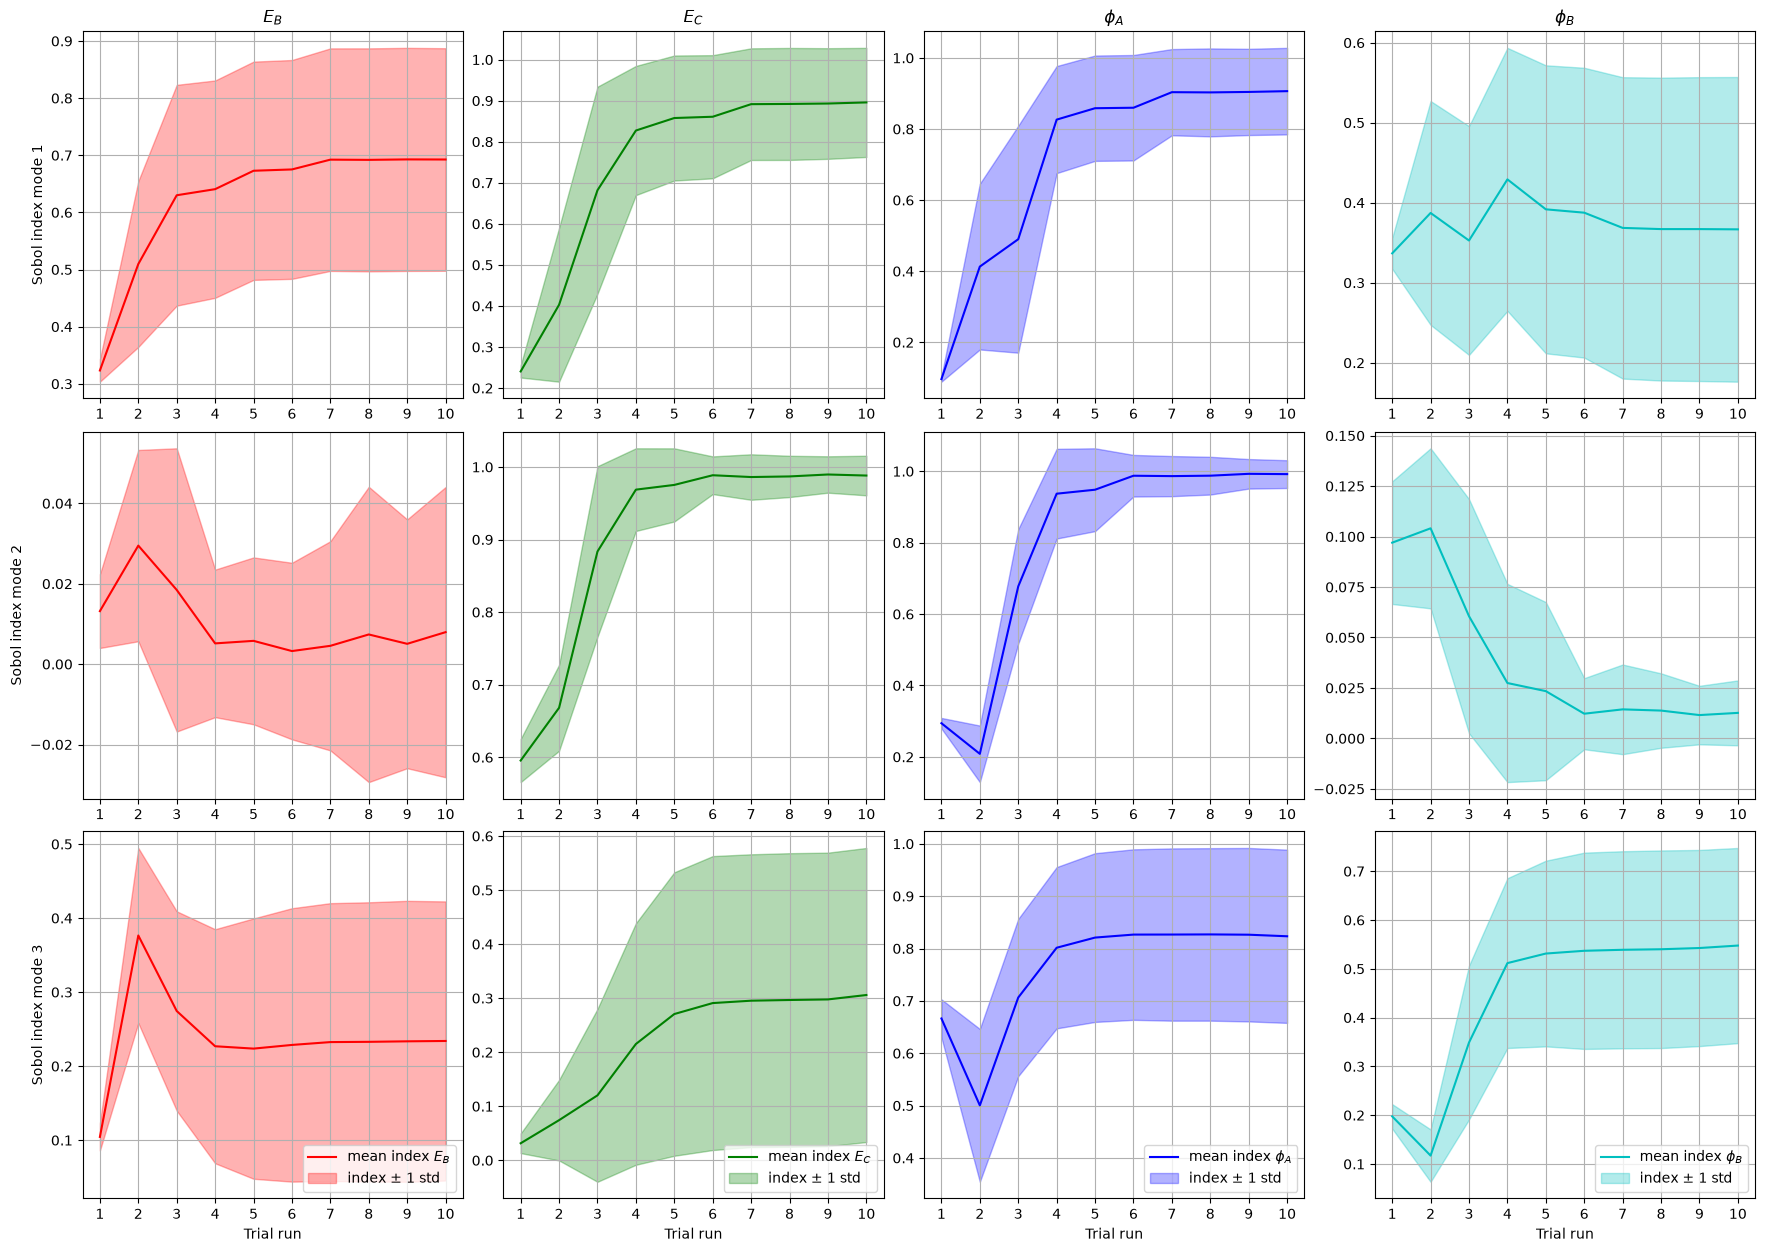

In [6]:
# Plot Sobol indices
plot_sobol_indices_cal()

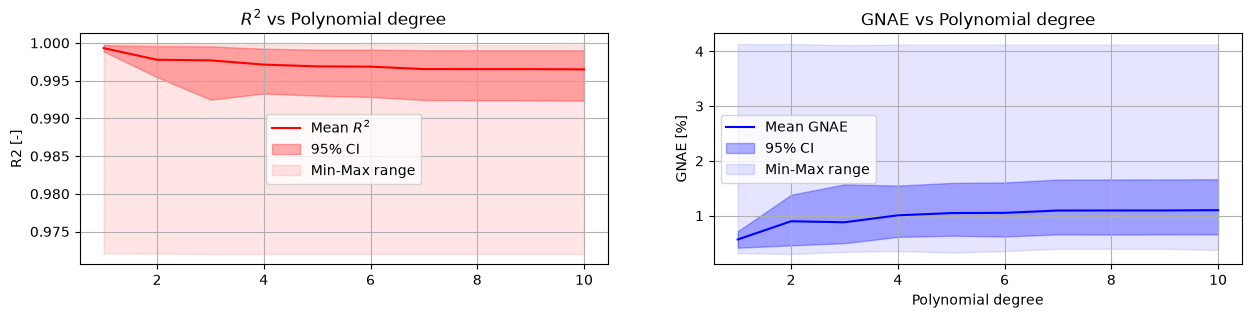

In [7]:
# Plot R^2 and GNAE errors for different truncation degrees
plot_errors("Calibration_Surrogate")

In [8]:
# Predictive model for calibration surrogate
X_train_val, X_test_val, U_train_val, U_test_val = train_test_split(X, U, test_size=0.2, random_state=42)
X_train = ot.Sample(X_train_val)
X_test = ot.Sample(X_test_val)
U_train = ot.Sample(U_train_val)
U_test = ot.Sample(U_test_val)

pce_models, pca, results = train_PCE(X_train, U_train, total_degree=7)

# Saving model
study = ot.Study()
study.setStorageManager(ot.XMLStorageManager("Logs\\Calibration_Surrogate\\calsur_pce_model.xml"))

## Save PCE model per mode
for i, model in enumerate(pce_models):
    model_i = results[i].getMetaModel()
    study.add(f"pce_model_mode_{i+1}", model_i)
    study.save()
dump(pca, "Logs\\Calibration_Surrogate\\calsur_pca_model.joblib")

['Logs\\Calibration_Surrogate\\calsur_pca_model.joblib']

Text(0.5, 1.0, 'Predicted deformation for test input [15000, 87000, 40.7, 37.2]')

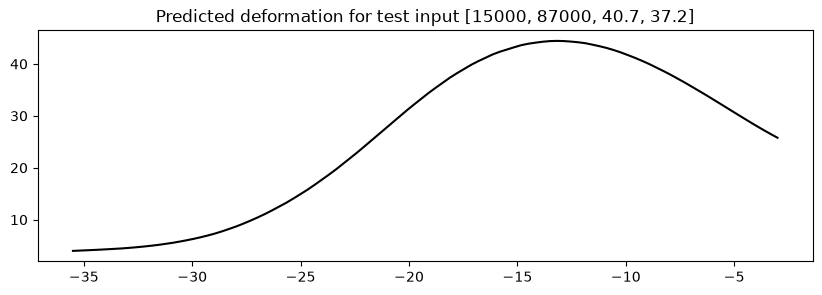

In [9]:
# Load model (not necessary if just trained, but useful for complicated models or multiple models)
study = ot.Study()
study.setStorageManager(
ot.XMLStorageManager("Logs\\Calibration_Surrogate\\calsur_pce_model.xml")
)

study.load()

## PCE models per mode
models = []
for i in range(1, n_modes + 1):
    mode_i_model = ot.Function()
    study.fillObject(f"pce_model_mode_{i}", mode_i_model) 
    models.append(mode_i_model)

x_test = [15000, 87000, 40.7, 37.2]

a_pred = np.array([model(x_test)[0] for model in models]).reshape(1, -1)
pca_loaded = load("Logs\\Calibration_Surrogate\\calsur_pca_model.joblib")

predict_test = pca_loaded.inverse_transform(a_pred)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(Z, predict_test[0], label='Predicted', color='k')
ax.set_title(f"Predicted deformation for test input {x_test}")

min R_sq:          0.994
GNEA:              1.015%
max difference:    1.56 mm, between FEM and PCE


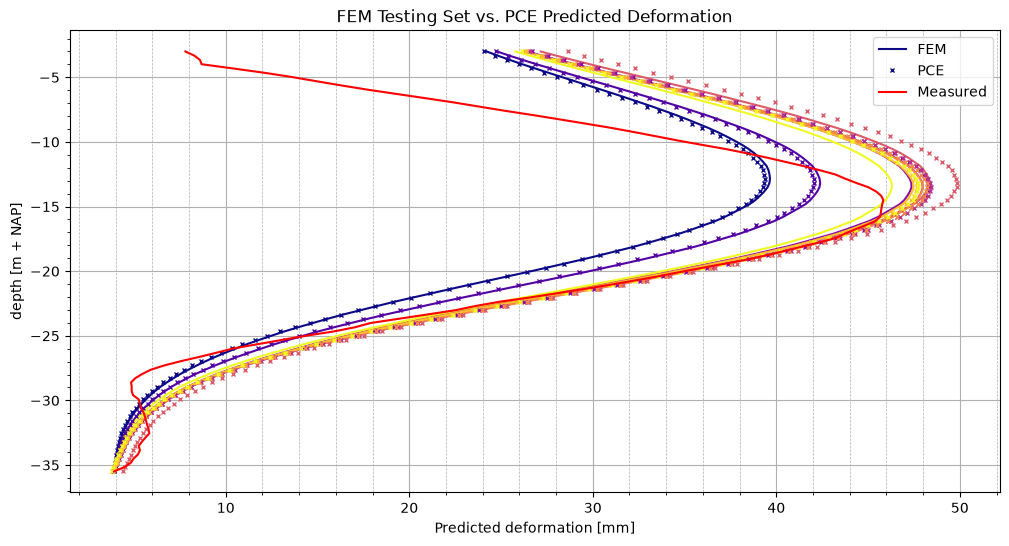

In [10]:
# Test the calibration surrogate model against testing set
U_meas = import_measurements("Logs\\inclino.csv", Z)


errors, R_sq, GNEA, maxdif = test_model(pca, pce_models, X_test_val, U_test_val, Z, U_meas)

print(f"min R_sq: {np.min(R_sq):>14.3f}")
print(f"GNEA: {np.mean(GNEA):>18.3f}%")
print(f"max difference: {np.max(maxdif):>7.2f} mm, between FEM and PCE")

In [11]:
# define parameter ranges for calibration
n = 1
params = define_param_list(X, n, U_meas, verbose=False)

NRSME_deform, NRSME_slope, RSME_deform, RSME_slope, U_predicted, theta_predicted = run_calibration(pce_models, pca, params, Z, U_meas)

NRSME_avg = np.array(NRSME_deform) + np.array(NRSME_slope)/2
print()
print(f'optimal set: {np.argmin(NRSME_avg)}')
print(f'optimal NRSME value: {NRSME_avg[np.argmin(NRSME_avg)]}')
print(f'set of optimal parameters: {params[np.argmin(NRSME_avg)]}')
print()


Iteration 1: X_i = [9.00e+03 5.80e+04 3.87e+01 3.36e+01]
optimal set: 0
optimal NRSME value: 0.19317394628280699
set of optimal parameters: [9.00e+03 5.80e+04 3.87e+01 3.36e+01]



First-order Sobol indices: E_B: 0.000 E_C: 0.000 phi_A: 0.000 phi_B: 0.000
Total-order Sobol indices: E_B: 0.771 E_C: 0.985 phi_A: 0.881 phi_B: 0.246

First-order Sobol indices: E_B: 0.000 E_C: 0.000 phi_A: 0.000 phi_B: 0.000
Total-order Sobol indices: E_B: 0.002 E_C: 0.999 phi_A: 1.000 phi_B: 0.008

First-order Sobol indices: E_B: 0.199 E_C: 0.000 phi_A: 0.237 phi_B: 0.000
Total-order Sobol indices: E_B: 0.221 E_C: 0.031 phi_A: 0.801 phi_B: 0.543

Variance ratio PCA: [0.969 0.029 0.003]
Total importance per parameter: [0.748, 0.983, 0.885, 0.24]


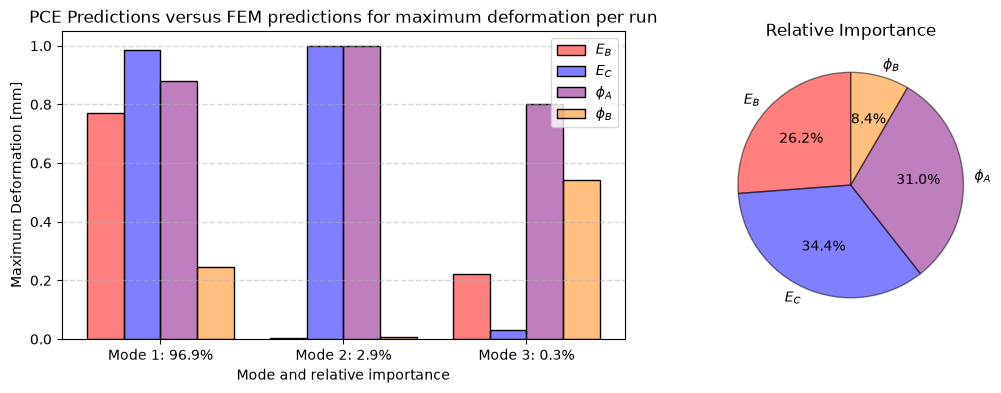

In [12]:
# Sobol indices for calibration parameters
Sobol_EB, Sobol_EC, Sobol_phi_A, Sobol_phi_B = determine_sobol(results, X_train, verbose = True)

plot_sobol(pca, Sobol_EB, Sobol_EC, Sobol_phi_A, Sobol_phi_B)